# Week 7 · Bottle Count
**Rayna Jong | Computer vision workshop**

A café worker can take one photo of a tray of bottles and get an estimated count. The notebook shows which bottles it counted by drawing a box and a confidence score around each one. The worker can check the boxes before using the number.

I chose **object recognition (object detection)** because I need both the count and the location of each bottle. This is a small solo prototype in Google Colab.

In [ ]:
from io import BytesIO
from pathlib import Path
import re

from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
photos = []
for filename, data in sorted(uploaded.items()):
    match = re.fullmatch(r"(\d+)_(.+)_(\d+)\.(jpg|jpeg|png)", Path(filename).name, re.I)
    if not match:
        raise ValueError(f"Rename {filename} using the format 03_overlap_2.jpg, then upload again.")
    with Image.open(BytesIO(data)) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
    photos.append((filename, match[2], int(match[3]), image))

if len(photos) < 10:
    raise ValueError("Upload at least 10 photos together.")
for filename, condition, actual, image in photos:
    print(f"{filename}: manual count = {actual}")

Saving 01_water_1.jpg to 01_water_1.jpg
Saving 10_cartons_0.jpg to 10_cartons_0.jpg
Saving 09_mixed_2.jpg to 09_mixed_2.jpg
Saving 08_angle_3.jpg to 08_angle_3.jpg
Saving 07_dim_2.jpg to 07_dim_2.jpg
Saving 06_overlap_3.jpg to 06_overlap_3.jpg
Saving 05_all_7.jpg to 05_all_7.jpg
Saving 04_juice_syrup_2.jpg to 04_juice_syrup_2.jpg
Saving 03_wine_2.jpg to 03_wine_2.jpg
Saving 02_water_3.jpg to 02_water_3.jpg
01_water_1.jpg: manual count = 1
02_water_3.jpg: manual count = 3
03_wine_2.jpg: manual count = 2
04_juice_syrup_2.jpg: manual count = 2
05_all_7.jpg: manual count = 7
06_overlap_3.jpg: manual count = 3
07_dim_2.jpg: manual count = 2
08_angle_3.jpg: manual count = 3
09_mixed_2.jpg: manual count = 2
10_cartons_0.jpg: manual count = 0


In [ ]:
import torch
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT
model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=weights).to(device).eval()
to_tensor = weights.transforms()
bottle_label = weights.meta["categories"].index("bottle")

predictions = {}
with torch.inference_mode():
    for filename, condition, actual, image in photos:
        output = model([to_tensor(image).to(device)])[0]
        predictions[filename] = [
            (box.tolist(), score.item())
            for box, label, score in zip(output["boxes"].cpu(),
                                         output["labels"].cpu(),
                                         output["scores"].cpu())
            if label.item() == bottle_label
        ]
print(f"Processed {len(photos)} photos.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 159MB/s]


Processed 10 photos.


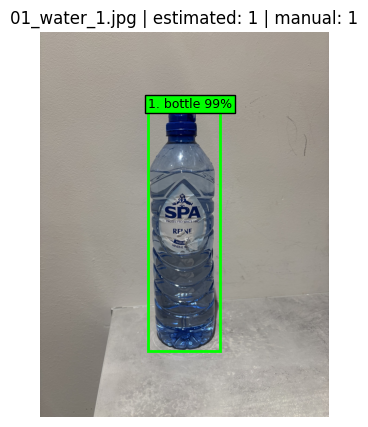

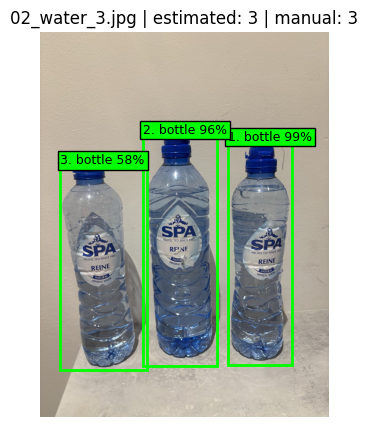

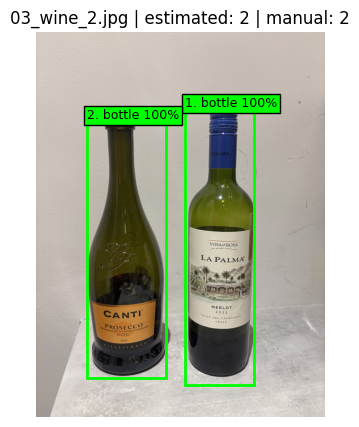

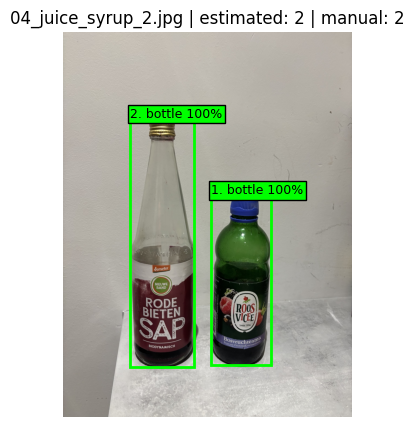

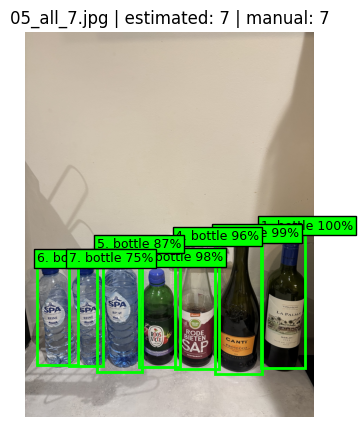

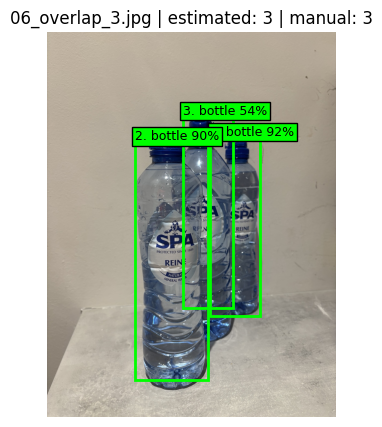

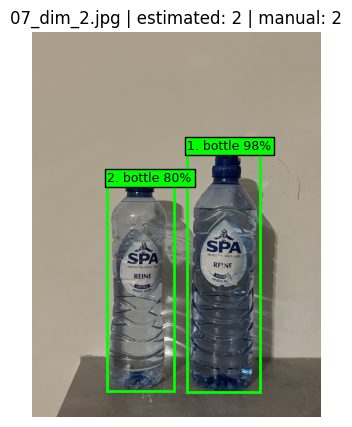

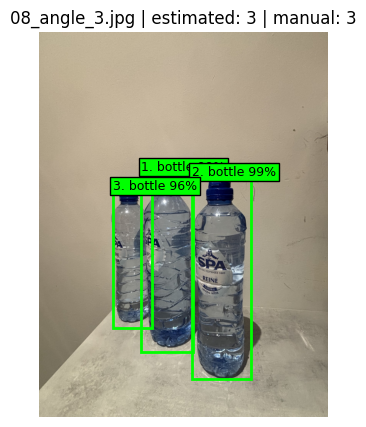

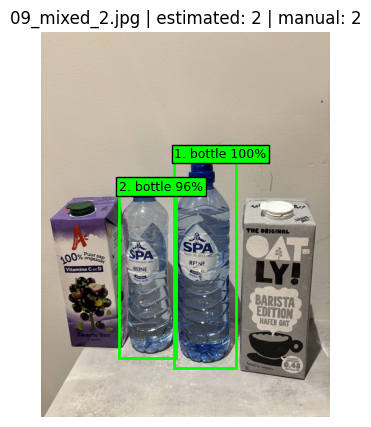

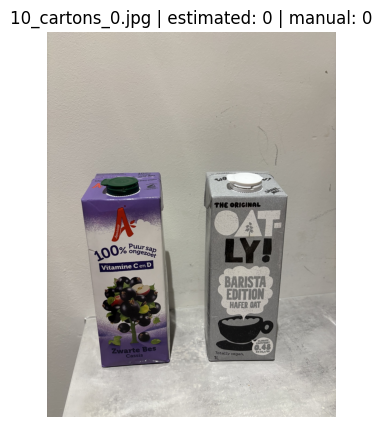

,photo,condition,manual_count,estimated_count,absolute_error
0,01_water_1.jpg,water,1,1,0
1,02_water_3.jpg,water,3,3,0
2,03_wine_2.jpg,wine,2,2,0
3,04_juice_syrup_2.jpg,juice_syrup,2,2,0
4,05_all_7.jpg,all,7,7,0
5,06_overlap_3.jpg,overlap,3,3,0
6,07_dim_2.jpg,dim,2,2,0
7,08_angle_3.jpg,angle,3,3,0
8,09_mixed_2.jpg,mixed,2,2,0
9,10_cartons_0.jpg,cartons,0,0,0


Mean absolute count error: 0.00 bottles per photo
Exact counts: 10 out of 10 photos


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

threshold = 0.50
rows = []
for filename, condition, actual, image in photos:
    kept = [(box, score) for box, score in predictions[filename] if score >= threshold]
    estimate = len(kept)
    rows.append({"photo": filename, "condition": condition, "manual_count": actual,
                 "estimated_count": estimate, "absolute_error": abs(estimate - actual)})
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(image)
    for number, ((x1, y1, x2, y2), score) in enumerate(kept, start=1):
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False,
                               edgecolor="lime", linewidth=2))
        ax.text(x1, y1, f"{number}. bottle {score:.0%}", color="black",
                fontsize=9, bbox={"facecolor": "lime", "pad": 2})
    ax.set_title(f"{filename} | estimated: {estimate} | manual: {actual}")
    ax.axis("off")
    plt.show()
    plt.close(fig)

results = pd.DataFrame(rows)
display(results)
print(f"Mean absolute count error: {results.absolute_error.mean():.2f} bottles per photo")
print(f"Exact counts: {results.absolute_error.eq(0).sum()} out of {len(results)} photos")
results.to_csv("week7_results.csv", index=False)